<a href="https://colab.research.google.com/github/lessouffrances/Algo/blob/main/homework_3_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 3

## Part 2: Neuron Net
### 1) train perceptron





Scikit-learn compatible format:
Features shape (Num_of_records, Dimension): (11, 2)
Target shape (Num_of_records): (11,)


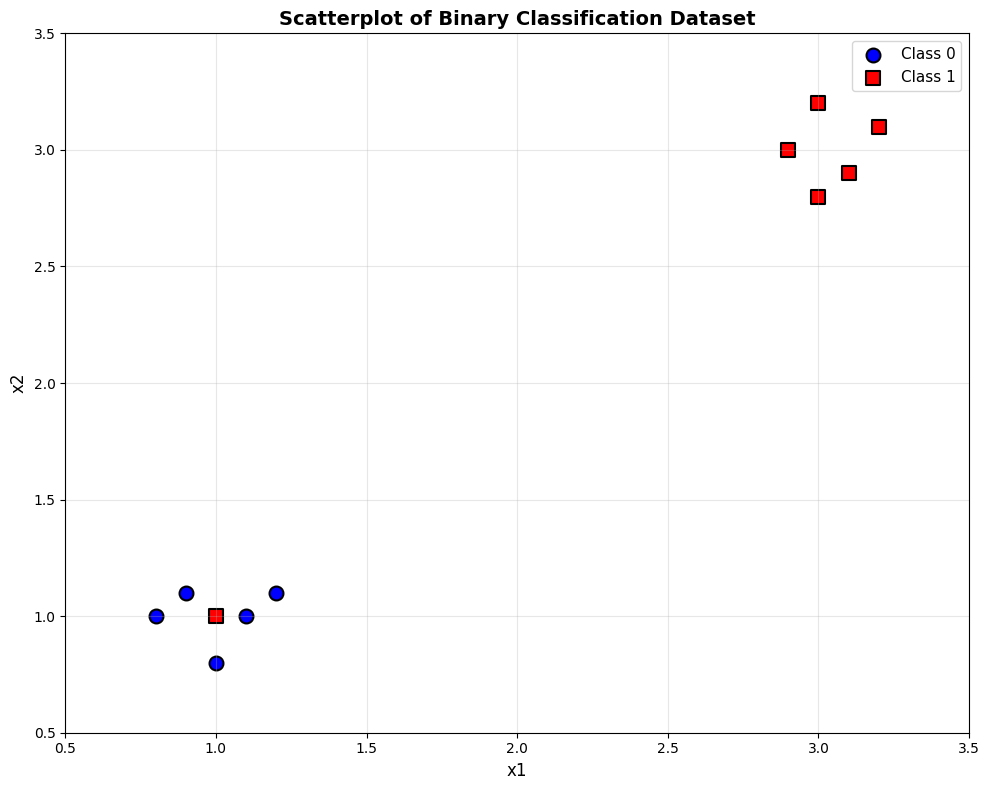

Step 0 (Initial): w1=0.7300, w2=-1.0000, b=1.5000, Total Errors=6
Step 1: Trained on sample 1 (np.float64(0.9), np.float64(1.1), np.int64(0))
         Updated weights: w1=0.6400, w2=-1.1100, b=1.4000
         Total Errors on dataset: 4

Step 2: Trained on sample 2 (np.float64(1.0), np.float64(0.8), np.int64(0))
         Updated weights: w1=0.5400, w2=-1.1900, b=1.3000
         Total Errors on dataset: 1

Step 3: Trained on sample 3 (np.float64(1.1), np.float64(1.0), np.int64(0))
         Updated weights: w1=0.4300, w2=-1.2900, b=1.2000
         Total Errors on dataset: 1

Step 4: Trained on sample 4 (np.float64(0.8), np.float64(1.0), np.int64(0))
         Updated weights: w1=0.3500, w2=-1.3900, b=1.1000
         Total Errors on dataset: 4

Step 5: Trained on sample 5 (np.float64(1.2), np.float64(1.1), np.int64(0))
         Updated weights: w1=0.3500, w2=-1.3900, b=1.1000
         Total Errors on dataset: 4

Step 6: Trained on sample 6 (np.float64(3.1), np.float64(2.9), np.int64(1))
   

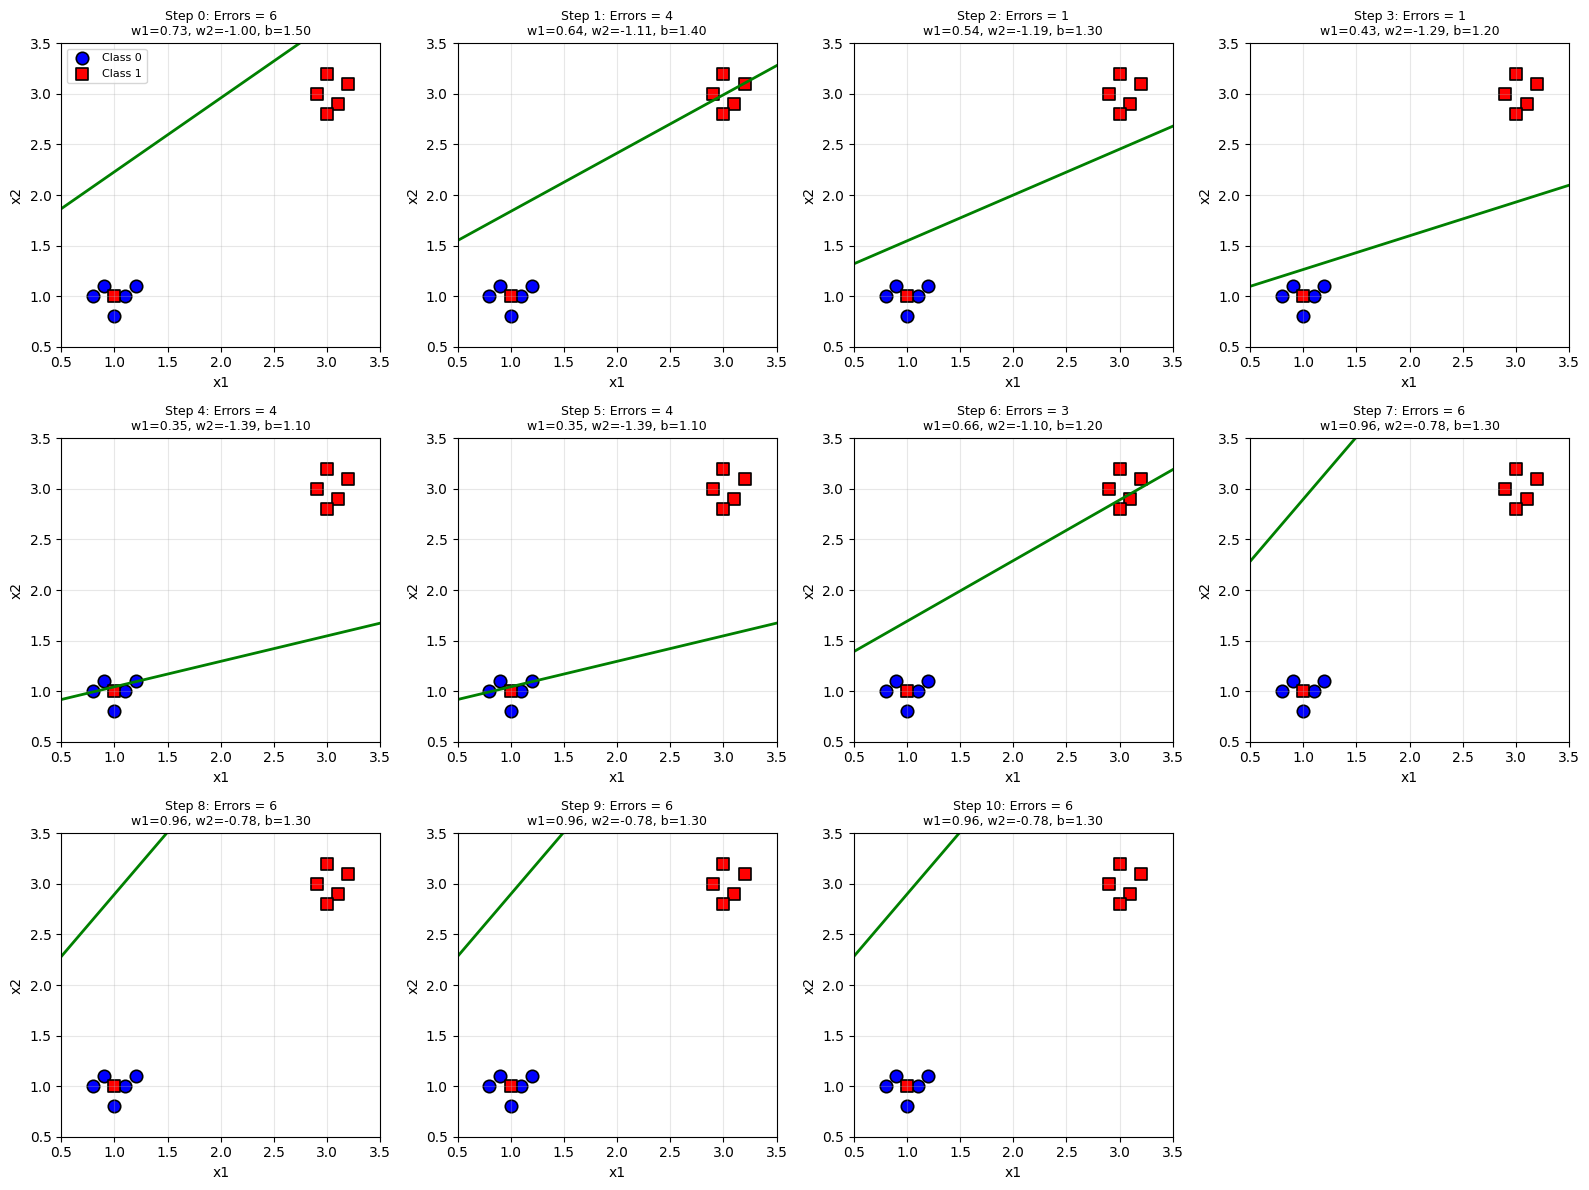

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create the dataset with schema (x1, x2, y)
data = [
    (0.9, 1.1, 0),
    (1.0, 0.8, 0),
    (1.1, 1.0, 0),
    (0.8, 1.0, 0),
    (1.2, 1.1, 0),
    (3.1, 2.9, 1),
    (3.0, 3.2, 1),
    (2.9, 3.0, 1),
    (3.2, 3.1, 1),
    (3.0, 2.8, 1),
    (1.0, 1.0, 1)
]

df = pd.DataFrame(data, columns=['x1', 'x2', 'y'])
X = df[['x1', 'x2']].values
y = df['y'].values

print(f"\n\nScikit-learn compatible format:")
print(f"Features shape (Num_of_records, Dimension): {X.shape}")
print(f"Target shape (Num_of_records): {y.shape}")

# Create the scatterplot
plt.figure(figsize=(10, 8))

# Separate the classes
class_0_mask = y == 0
class_1_mask = y == 1

# Plot each class with different colors and markers
plt.scatter(X[class_0_mask, 0], X[class_0_mask, 1],
           c='blue', marker='o', s=100, label='Class 0', edgecolors='black', linewidth=1.5)
plt.scatter(X[class_1_mask, 0], X[class_1_mask, 1],
           c='red', marker='s', s=100, label='Class 1', edgecolors='black', linewidth=1.5)

# Add labels and title
plt.xlabel('x1', fontsize=12)
plt.ylabel('x2', fontsize=12)
plt.title('Scatterplot of Binary Classification Dataset', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

# Set axis limits with some padding
plt.xlim(0.5, 3.5)
plt.ylim(0.5, 3.5)

plt.tight_layout()
plt.show()


def train_perceptron(training_record, learning_rate, w1, w2, b):
    """
    Train perceptron on a single training record.

    Parameters:
    - training_record: tuple (x1, x2, y)
    - learning_rate: learning rate for weight updates
    - w1, w2, b: current weights and bias

    Returns:
    - (w1_new, w2_new, b_new): updated weights and bias
    """
    x1, x2, y_true = training_record

    # Compute perceptron output
    f_x = w1 * x1 + w2 * x2 + b

    # Predict class (0 if f(x) < 0, 1 if f(x) >= 0)
    y_pred = 1 if f_x >= 0 else 0

    # Update weights if misclassified
    if y_pred != y_true:
        error_signal = y_true - y_pred
        w1_new = w1 + learning_rate * error_signal * x1
        w2_new = w2 + learning_rate * error_signal * x2
        b_new = b + learning_rate * error_signal
    else:
        w1_new, w2_new, b_new = w1, w2, b

    return w1_new, w2_new, b_new

def calculate_total_error(X, y, w1, w2, b):
    """Calculate the number of misclassifications on the entire dataset."""
    errors = 0
    for i in range(len(X)):
        x1, x2 = X[i]
        y_true = y[i]
        f_x = w1 * x1 + w2 * x2 + b
        y_pred = 0 if f_x >= 0 else 1
        if y_pred != y_true:
            errors += 1
    return errors

def plot_hyperplane(X, y, w1, w2, b, step, error, ax):
    """Plot the data points and current hyperplane."""
    class_0_mask = y == 0
    class_1_mask = y == 1

    ax.scatter(X[class_0_mask, 0], X[class_0_mask, 1],
               c='blue', marker='o', s=80, label='Class 0',
               edgecolors='black', linewidth=1.2)
    ax.scatter(X[class_1_mask, 0], X[class_1_mask, 1],
               c='red', marker='s', s=80, label='Class 1',
               edgecolors='black', linewidth=1.2)

    # Plot decision boundary
    x1_line = np.linspace(0.5, 3.5, 100)
    x2_line = -(w1 * x1_line + b) / w2
    ax.plot(x1_line, x2_line, 'g-', linewidth=2)

    ax.set_xlabel('x1', fontsize=10)
    ax.set_ylabel('x2', fontsize=10)
    ax.set_title(f'Step {step}: Errors = {error}\nw1={w1:.2f}, w2={w2:.2f}, b={b:.2f}',
                 fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0.5, 3.5)
    ax.set_ylim(0.5, 3.5)
    if step == 0:
        ax.legend(fontsize=8, loc='upper left')

# Initialize parameters
w1 = 0.73
w2 = -1.0
b = 1.5
learning_rate = 0.1

# Create figure with subplots for each step
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

# Plot initial state
initial_error = calculate_total_error(X, y, w1, w2, b)
plot_hyperplane(X, y, w1, w2, b, 0, initial_error, axes[0])
print(f"Step 0 (Initial): w1={w1:.4f}, w2={w2:.4f}, b={b:.4f}, Total Errors={initial_error}")

# Train on each record sequentially
for step in range(1, 11):
    # Get the training record (step-1 because we're 0-indexed)
    training_record = (X[step-1, 0], X[step-1, 1], y[step-1])

    # Train on this single record
    w1, w2, b = train_perceptron(training_record, learning_rate, w1, w2, b)

    # Calculate error on entire dataset
    total_error = calculate_total_error(X, y, w1, w2, b)

    # Plot the result
    plot_hyperplane(X, y, w1, w2, b, step, total_error, axes[step])

    # Print report
    print(f"Step {step}: Trained on sample {step} {training_record}")
    print(f"         Updated weights: w1={w1:.4f}, w2={w2:.4f}, b={b:.4f}")
    print(f"         Total Errors on dataset: {total_error}")
    print()

# Remove the last empty subplot
axes[11].axis('off')

plt.tight_layout()
plt.show()


### 2) train neuron net



In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
# import matplotlib.animation as animation
# from IPython.display import HTML

def generate_noisy_dataset(x_range, feature_transform, true_feature, number_of_samples, epsilon):
    x_values = np.random.uniform(x_range[0], x_range[1], number_of_samples)
    num_features = len(feature_transform)
    X = np.zeros((number_of_samples, num_features))

    for i, func in enumerate(feature_transform):
        X[:, i] = func(x_values)

    y_true = feature_transform[true_feature](x_values)
    noise = np.random.uniform(-epsilon, epsilon, number_of_samples)
    y = y_true + noise

    return X, y, x_values

# Define features
feature_transform = [
    lambda x: 2*x + 3,           # Linear (TRUE)
    lambda x: x**2 - 3*x + 2,    # Quadratic
    lambda x: 0.5*x**3 - x**2 + x  # Cubic
]

# Generate dataset
x_range = [0, 1]
noise = 0.1
n_samples = 100
true_feature = 0

X, y, x_values = generate_noisy_dataset(x_range, feature_transform, true_feature, n_samples, noise)
X_train, X_test, y_train, y_test, x_train, x_test = train_test_split(
    X, y, x_values, test_size=0.2, random_state=42
)

# Convert to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train)
y_train_tensor = torch.FloatTensor(y_train).reshape(-1, 1)
X_test_tensor = torch.FloatTensor(X_test)
y_test_tensor = torch.FloatTensor(y_test).reshape(-1, 1)

print(f"{'='*60}")
print(f"Dataset: True Function: 2x + 3, Noise: {noise}, Samples: {n_samples}")
print(f"Training samples: {len(X_train)}, Test samples: {len(X_test)}")
print('='*60)

# NEURAL NETWORK DEFINITION
class SimpleNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, activation):
        super(SimpleNN, self).__init__()
        self.layer1 = nn.Linear(input_dim, hidden_dim)
        self.activation = activation
        self.layer2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.layer1(x)
        x = self.activation(x)
        x = self.layer2(x)
        return x

# ACTIVATION AND LOSS FUNCTIONS (Regression-appropriate only)
activations = {
    'relu': nn.ReLU(),
    'tanh': nn.Tanh(),
    'sigmoid': nn.Sigmoid(),
    'leaky_relu': nn.LeakyReLU(0.01),
}

losses = {
    'mse': nn.MSELoss(),
    'mae': nn.L1Loss(),
    'huber': nn.HuberLoss(),
}

# TRAINING FUNCTION FOR SINGLE COMBINATION
def train_single_combination(X_train, y_train, X_test, y_test,
                             activation_fn, loss_fn,
                             n_epochs=200, hidden_dim=20, lr=0.01, capture_every=5):
    """
    Train a FRESH neural network for one activation-loss combination.
    Captures snapshots during training for animation.
    """

    # CREATE NEW MODEL (fresh initialization)
    model = SimpleNN(input_dim=3, hidden_dim=hidden_dim, output_dim=1, activation=activation_fn)
    criterion = loss_fn
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Storage for animation
    history = {
        'epochs': [],
        'train_losses': [],
        'test_losses': [],
        'predictions': []
    }

    # Create test points for smooth prediction line
    x_line = torch.linspace(0, 1, 100).reshape(-1, 1)
    X_line = torch.zeros(100, 3)
    for i, func in enumerate(feature_transform):
        X_line[:, i] = torch.FloatTensor([func(x.item()) for x in x_line])

    # Training loop
    for epoch in range(n_epochs):
        # TRAINING
        model.train()
        optimizer.zero_grad()

        outputs = model(X_train)
        loss = criterion(outputs, y_train)

        loss.backward()
        optimizer.step()

        # Capture snapshots for animation
        if epoch % capture_every == 0 or epoch == n_epochs - 1:
            model.eval()
            with torch.no_grad():
                # Get predictions for visualization
                predictions = model(X_line).numpy().flatten()

                # Calculate test loss
                test_pred = model(X_test)
                test_loss = criterion(test_pred, y_test)

                history['epochs'].append(epoch)
                history['train_losses'].append(loss.item())
                history['test_losses'].append(test_loss.item())
                history['predictions'].append(predictions)

    # Final evaluation
    model.eval()
    with torch.no_grad():
        final_train_pred = model(X_train)
        final_train_loss = criterion(final_train_pred, y_train).item()

        final_test_pred = model(X_test)
        final_test_loss = criterion(final_test_pred, y_test).item()

    return model, history, final_train_loss, final_test_loss


# ANIMATION FUNCTION
def create_animation(history, x_train, y_train, activation_name, loss_name):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Setup for left plot (predictions)
    x_line = np.linspace(0, 1, 100)
    y_true_line = 2 * x_line + 3  # True function

    ax1.scatter(x_train, y_train, alpha=0.5, s=30, c='blue', label='Training Data')
    ax1.plot(x_line, y_true_line, 'g--', linewidth=2, label='True Function: 2x+3')
    line, = ax1.plot([], [], 'r-', linewidth=2.5, label='Model Prediction')

    ax1.set_xlim(0, 1)
    ax1.set_ylim(2.5, 5.5)
    ax1.set_xlabel('x', fontsize=12)
    ax1.set_ylabel('y', fontsize=12)
    ax1.set_title(f'Activation: {activation_name.upper()}, Loss: {loss_name.upper()}', fontsize=13, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(True, alpha=0.3)

    epoch_text = ax1.text(0.02, 0.98, '', transform=ax1.transAxes,
                          fontsize=11, verticalalignment='top',
                          bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    # Setup for right plot (loss curves)
    ax2.set_xlim(0, history['epochs'][-1])
    max_loss = max(max(history['train_losses']), max(history['test_losses']))
    ax2.set_ylim(0, max_loss * 1.1)
    ax2.set_xlabel('Epoch', fontsize=12)
    ax2.set_ylabel('Loss', fontsize=12)
    ax2.set_title('Training Progress', fontsize=13, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    train_loss_line, = ax2.plot([], [], 'b-', linewidth=2, label='Train Loss')
    test_loss_line, = ax2.plot([], [], 'r--', linewidth=2, label='Test Loss')
    ax2.legend(fontsize=10)

    def init():
        line.set_data([], [])
        train_loss_line.set_data([], [])
        test_loss_line.set_data([], [])
        epoch_text.set_text('')
        return line, train_loss_line, test_loss_line, epoch_text

    def animate(frame):
        # Update prediction line
        line.set_data(x_line, history['predictions'][frame])

        # Update loss curves
        train_loss_line.set_data(history['epochs'][:frame+1], history['train_losses'][:frame+1])
        test_loss_line.set_data(history['epochs'][:frame+1], history['test_losses'][:frame+1])

        # Update epoch text
        epoch_text.set_text(f"Epoch: {history['epochs'][frame]}\n" +
                           f"Train Loss: {history['train_losses'][frame]:.4f}\n" +
                           f"Test Loss: {history['test_losses'][frame]:.4f}")

        return line, train_loss_line, test_loss_line, epoch_text

    ani = animation.FuncAnimation(fig, animate, init_func=init,
                                 frames=len(history['epochs']),
                                 interval=100, blit=True, repeat=True)

    plt.close(fig)
    return ani

# TRAIN ALL COMBINATIONS (EACH WITH FRESH NN)
print("\n" + "="*70)
print("TRAINING NEURAL NETWORKS - ALL COMBINATIONS")
print("="*70)
print(f"\nArchitecture: 3 inputs → 20 hidden → 1 output")
print(f"Optimizer: Adam (lr=0.01)")
print(f"Epochs: 200")
print("="*70)

results = {}
animations = {}

for activation_name, activation_fn in activations.items():
    for loss_name, loss_fn in losses.items():
        combo_name = f"{activation_name}_{loss_name}"
        print(f"\n[{combo_name}] Training FRESH model...")

        # Train NEW model for this combination
        model, history, final_train_loss, final_test_loss = train_single_combination(
            X_train_tensor, y_train_tensor,
            X_test_tensor, y_test_tensor,
            activation_fn, loss_fn,
            n_epochs=200, hidden_dim=20, lr=0.01, capture_every=5
        )

        results[combo_name] = {
            'model': model,
            'history': history,
            'final_train_loss': final_train_loss,
            'final_test_loss': final_test_loss
        }

        # Create animation
        ani = create_animation(history, x_train, y_train, activation_name, loss_name)
        animations[combo_name] = ani

        print(f"  ✓ Final Train Loss: {final_train_loss:.4f}")
        print(f"  ✓ Final Test Loss:  {final_test_loss:.4f}")

# RESULTS SUMMARY
print("\n" + "="*70)
print("RESULTS SUMMARY - ALL COMBINATIONS")
print("="*70)

print(f"\n{'Combination':<25} {'Train Loss':<15} {'Test Loss':<15} {'Gap':<10}")
print("-" * 70)

sorted_results = sorted(results.items(), key=lambda x: x[1]['final_test_loss'])

for combo_name, result in sorted_results:
    train_loss = result['final_train_loss']
    test_loss = result['final_test_loss']
    gap = test_loss - train_loss
    print(f"{combo_name:<25} {train_loss:<15.4f} {test_loss:<15.4f} {gap:<10.4f}")

# Find best combination
best_combo = sorted_results[0]
print(f"\n Best Combination (by test loss): {best_combo[0].upper()}")
print(f"   Train Loss: {best_combo[1]['final_train_loss']:.4f}")
print(f"   Test Loss:  {best_combo[1]['final_test_loss']:.4f}")

# DISPLAY ALL ANIMATIONS
print("\n" + "="*70)
print("DISPLAYING ALL ANIMATIONS")
print("="*70)
print(f"\nGenerating HTML for all {len(animations)} combinations...")

# Display all animations
# from IPython.display import display

for combo_name in sorted_results:
    combo_key = combo_name[0]
    print(f"\n{'='*70}")
    print(f"ANIMATION: {combo_key.upper()}")
    print(f"Train Loss: {results[combo_key]['final_train_loss']:.4f}, Test Loss: {results[combo_key]['final_test_loss']:.4f}")
    print('='*70)
    # display(HTML(animations[combo_key].to_jshtml()))

print("\n" + "="*70)
print("ALL ANIMATIONS DISPLAYED")
print("="*70)

### Use various learning rates

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
# import matplotlib.animation as animation
# from IPython.display import HTML, display

def generate_noisy_dataset(x_range, feature_transform, true_feature, number_of_samples, epsilon):
    x_values = np.random.uniform(x_range[0], x_range[1], number_of_samples)
    num_features = len(feature_transform)
    X = np.zeros((number_of_samples, num_features))

    for i, func in enumerate(feature_transform):
        X[:, i] = func(x_values)

    y_true = feature_transform[true_feature](x_values)
    noise = np.random.uniform(-epsilon, epsilon, number_of_samples)
    y = y_true + noise

    return X, y, x_values

# Define features
feature_transform = [
    lambda x: 2*x + 3,           # Linear (TRUE)
    lambda x: x**2 - 3*x + 2,    # Quadratic
    lambda x: 0.5*x**3 - x**2 + x  # Cubic
]

# Generate dataset
x_range = [0, 1]
noise = 0.1
n_samples = 100
true_feature = 0

X, y, x_values = generate_noisy_dataset(x_range, feature_transform, true_feature, n_samples, noise)
X_train, X_test, y_train, y_test, x_train, x_test = train_test_split(
    X, y, x_values, test_size=0.2, random_state=42
)

# Convert to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train)
y_train_tensor = torch.FloatTensor(y_train).reshape(-1, 1)
X_test_tensor = torch.FloatTensor(X_test)
y_test_tensor = torch.FloatTensor(y_test).reshape(-1, 1)

print(f"{'='*60}")
print(f"Dataset: True Function: 2x + 3, Noise: {noise}, Samples: {n_samples}")
print(f"Training samples: {len(X_train)}, Test samples: {len(X_test)}")
print('='*60)

class SimpleNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, activation):
        super(SimpleNN, self).__init__()
        self.layer1 = nn.Linear(input_dim, hidden_dim)
        self.activation = activation
        self.layer2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.layer1(x)
        x = self.activation(x)
        x = self.layer2(x)
        return x

activations = {
    'relu': nn.ReLU(),
    'tanh': nn.Tanh(),
    'sigmoid': nn.Sigmoid(),
    'leaky_relu': nn.LeakyReLU(0.01),
}

losses = {
    'mse': nn.MSELoss(),
    'mae': nn.L1Loss(),
    'huber': nn.HuberLoss(),
}

# LEARNING RATES TO EXPERIMENT WITH
learning_rates = [0.001, 0.01, 0.1, 1, 10]

def train_single_combination(X_train, y_train, X_test, y_test,
                             activation_fn, loss_fn,
                             n_epochs=200, hidden_dim=20, lr=0.01, capture_every=5):
    """Train a FRESH neural network for one combination."""

    # CREATE NEW MODEL
    model = SimpleNN(input_dim=3, hidden_dim=hidden_dim, output_dim=1, activation=activation_fn)
    criterion = loss_fn
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Storage for animation
    history = {
        'epochs': [],
        'train_losses': [],
        'test_losses': [],
        'predictions': []
    }

    # Create test points for smooth prediction line
    x_line = torch.linspace(0, 1, 100).reshape(-1, 1)
    X_line = torch.zeros(100, 3)
    for i, func in enumerate(feature_transform):
        X_line[:, i] = torch.FloatTensor([func(x.item()) for x in x_line])

    # Training loop with overflow protection
    for epoch in range(n_epochs):
        model.train()
        optimizer.zero_grad()

        outputs = model(X_train)
        loss = criterion(outputs, y_train)

        # Check for NaN or Inf
        if torch.isnan(loss) or torch.isinf(loss):
            print(f"    ⚠ Training diverged at epoch {epoch}")
            break

        loss.backward()
        optimizer.step()

        # Capture snapshots for animation
        if epoch % capture_every == 0 or epoch == n_epochs - 1:
            model.eval()
            with torch.no_grad():
                predictions = model(X_line).numpy().flatten()
                test_pred = model(X_test)
                test_loss = criterion(test_pred, y_test)

                history['epochs'].append(epoch)
                history['train_losses'].append(loss.item())
                history['test_losses'].append(test_loss.item())
                history['predictions'].append(predictions)

    # Final evaluation
    model.eval()
    with torch.no_grad():
        final_train_pred = model(X_train)
        final_train_loss = criterion(final_train_pred, y_train).item()

        final_test_pred = model(X_test)
        final_test_loss = criterion(final_test_pred, y_test).item()

    return model, history, final_train_loss, final_test_loss

# ANIMATION FUNCTION
def create_animation(history, x_train, y_train, activation_name, loss_name, lr):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Left plot - predictions
    x_line = np.linspace(0, 1, 100)
    y_true_line = 2 * x_line + 3

    ax1.scatter(x_train, y_train, alpha=0.5, s=30, c='blue', label='Training Data')
    ax1.plot(x_line, y_true_line, 'g--', linewidth=2, label='True Function: 2x+3')
    line, = ax1.plot([], [], 'r-', linewidth=2.5, label='Model Prediction')

    ax1.set_xlim(0, 1)
    ax1.set_ylim(2.5, 5.5)
    ax1.set_xlabel('x', fontsize=12)
    ax1.set_ylabel('y', fontsize=12)
    ax1.set_title(f'{activation_name.upper()} + {loss_name.upper()} | LR={lr}',
                  fontsize=13, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(True, alpha=0.3)

    epoch_text = ax1.text(0.02, 0.98, '', transform=ax1.transAxes,
                          fontsize=11, verticalalignment='top',
                          bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    # Right plot - loss curves
    ax2.set_xlim(0, history['epochs'][-1])
    max_loss = max(max(history['train_losses']), max(history['test_losses']))
    ax2.set_ylim(0, max_loss * 1.1)
    ax2.set_xlabel('Epoch', fontsize=12)
    ax2.set_ylabel('Loss', fontsize=12)
    ax2.set_title('Training Progress', fontsize=13, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    train_loss_line, = ax2.plot([], [], 'b-', linewidth=2, label='Train Loss')
    test_loss_line, = ax2.plot([], [], 'r--', linewidth=2, label='Test Loss')
    ax2.legend(fontsize=10)

    def init():
        line.set_data([], [])
        train_loss_line.set_data([], [])
        test_loss_line.set_data([], [])
        epoch_text.set_text('')
        return line, train_loss_line, test_loss_line, epoch_text

    def animate(frame):
        line.set_data(x_line, history['predictions'][frame])
        train_loss_line.set_data(history['epochs'][:frame+1], history['train_losses'][:frame+1])
        test_loss_line.set_data(history['epochs'][:frame+1], history['test_losses'][:frame+1])

        epoch_text.set_text(f"Epoch: {history['epochs'][frame]}\n" +
                           f"Train Loss: {history['train_losses'][frame]:.4f}\n" +
                           f"Test Loss: {history['test_losses'][frame]:.4f}")

        return line, train_loss_line, test_loss_line, epoch_text

    # ani = animation.FuncAnimation(fig, animate, init_func=init,
                                #  frames=len(history['epochs']),
                                #  interval=100, blit=True, repeat=True)

    plt.close(fig)
    return ani

# TRAIN ALL COMBINATIONS
print("\n" + "="*70)
print("TRAINING NEURAL NETWORKS - GRID SEARCH")
print("="*70)
print(f"\nArchitecture: 3 inputs → 20 hidden → 1 output")
print(f"Activations: {list(activations.keys())}")
print(f"Losses: {list(losses.keys())}")
print(f"Learning Rates: {learning_rates}")
print(f"\nTotal Combinations: {len(activations) * len(losses) * len(learning_rates)}")
print("="*70)

results = {}
animations = {}
experiment_count = 0
total_experiments = len(activations) * len(losses) * len(learning_rates)

for lr in learning_rates:
    print(f"\n{'='*70}")
    print(f"LEARNING RATE: {lr}")
    print('='*70)

    for activation_name, activation_fn in activations.items():
        for loss_name, loss_fn in losses.items():
            experiment_count += 1
            combo_name = f"{activation_name}_{loss_name}_lr{lr}"

            print(f"\n[{experiment_count}/{total_experiments}] {combo_name}")

            # Train NEW model
            model, history, final_train_loss, final_test_loss = train_single_combination(
                X_train_tensor, y_train_tensor,
                X_test_tensor, y_test_tensor,
                activation_fn, loss_fn,
                n_epochs=200, hidden_dim=20, lr=lr, capture_every=5
            )

            results[combo_name] = {
                'activation': activation_name,
                'loss': loss_name,
                'lr': lr,
                'model': model,
                'history': history,
                'final_train_loss': final_train_loss,
                'final_test_loss': final_test_loss
            }

            # Create animation
            ani = create_animation(history, x_train, y_train, activation_name, loss_name, lr)
            animations[combo_name] = ani

            print(f"  ✓ Train Loss: {final_train_loss:.4f} | Test Loss: {final_test_loss:.4f}")


# RESULTS SUMMARY
print("\n" + "="*70)
print("RESULTS SUMMARY - ALL COMBINATIONS (Sorted by Test Loss)")
print("="*70)

print(f"\n{'Rank':<6} {'Combination':<35} {'LR':<8} {'Train Loss':<12} {'Test Loss':<12} {'Gap':<10}")
print("-" * 95)

sorted_results = sorted(results.items(), key=lambda x: x[1]['final_test_loss'])

for rank, (combo_name, result) in enumerate(sorted_results, 1):
    train_loss = result['final_train_loss']
    test_loss = result['final_test_loss']
    gap = test_loss - train_loss
    lr = result['lr']
    display_name = f"{result['activation']}_{result['loss']}"

    print(f"{rank:<6} {display_name:<35} {lr:<8} {train_loss:<12.4f} {test_loss:<12.4f} {gap:<10.4f}")

# Best and worst
best_combo = sorted_results[0]
worst_combo = sorted_results[-1]

print(f"\n{'='*70}")
print(f" BEST: {best_combo[0]}")
print(f"   Test Loss: {best_combo[1]['final_test_loss']:.4f}")
print(f"\n WORST: {worst_combo[0]}")
print(f"   Test Loss: {worst_combo[1]['final_test_loss']:.4f}")

# Summary by learning rate
print(f"\n{'='*70}")
print("SUMMARY BY LEARNING RATE")
print('='*70)

for lr in learning_rates:
    lr_results = {k: v for k, v in results.items() if v['lr'] == lr}
    avg_test_loss = np.mean([v['final_test_loss'] for v in lr_results.values()])
    best_in_lr = min(lr_results.items(), key=lambda x: x[1]['final_test_loss'])

    print(f"\nLR = {lr:>6}")
    print(f"  Average Test Loss: {avg_test_loss:.4f}")
    print(f"  Best Combination: {best_in_lr[0]} (Test Loss: {best_in_lr[1]['final_test_loss']:.4f})")

# DISPLAY ANIMATIONS (Top 5 and Bottom 5)
print("\n" + "="*70)
print("DISPLAYING ANIMATIONS - TOP 5 AND BOTTOM 5 PERFORMERS")
print("="*70)

print("\n TOP 5 PERFORMERS:")
for rank, (combo_name, result) in enumerate(sorted_results[:5], 1):
    print(f"\n{'-'*70}")
    print(f"RANK {rank}: {combo_name.upper()}")
    print(f"Train Loss: {result['final_train_loss']:.4f} | Test Loss: {result['final_test_loss']:.4f}")
    print('-'*70)
    # display(HTML(animations[combo_name].to_jshtml()))

print("\n BOTTOM 5 PERFORMERS:")
for rank, (combo_name, result) in enumerate(sorted_results[-5:], len(sorted_results)-4):
    print(f"\n{'-'*70}")
    print(f"RANK {rank}: {combo_name.upper()}")
    print(f"Train Loss: {result['final_train_loss']:.4f} | Test Loss: {result['final_test_loss']:.4f}")
    print('-'*70)
    # display(HTML(animations[combo_name].to_jshtml()))

print("\n" + "="*70)
print("ANIMATION DISPLAY COMPLETE")
print("="*70)
print(f"\nAll {len(animations)} animations available in 'animations' dictionary")
print("Access any animation: animations['activation_loss_lrX']")

### Observations for gradienets for w and b

Dataset: True Function: 2x + 3, Noise: 0.1, Samples: 100
Training samples: 80, Test samples: 20

TRAINING WITH GRADIENT TRACKING

Total Combinations: 60

LEARNING RATE: 0.001

[1/60] relu_mse_lr0.001
  ✓ Train: 0.2372 | Test: 0.2544

[2/60] relu_mae_lr0.001
  ✓ Train: 0.0666 | Test: 0.0627

[3/60] relu_huber_lr0.001
  ✓ Train: 0.1309 | Test: 0.1319

[4/60] tanh_mse_lr0.001
  ✓ Train: 0.7173 | Test: 0.8241

[5/60] tanh_mae_lr0.001
  ✓ Train: 0.5971 | Test: 0.6261

[6/60] tanh_huber_lr0.001
  ✓ Train: 0.2052 | Test: 0.2350

[7/60] sigmoid_mse_lr0.001
  ✓ Train: 1.7414 | Test: 1.9197

[8/60] sigmoid_mae_lr0.001
  ✓ Train: 0.9371 | Test: 1.0009

[9/60] sigmoid_huber_lr0.001
  ✓ Train: 0.5742 | Test: 0.6348

[10/60] leaky_relu_mse_lr0.001
  ✓ Train: 0.2336 | Test: 0.2325

[11/60] leaky_relu_mae_lr0.001
  ✓ Train: 0.3912 | Test: 0.3806

[12/60] leaky_relu_huber_lr0.001
  ✓ Train: 0.0612 | Test: 0.0603

LEARNING RATE: 0.01

[13/60] relu_mse_lr0.01
  ✓ Train: 0.0030 | Test: 0.0023

[14/60] rel

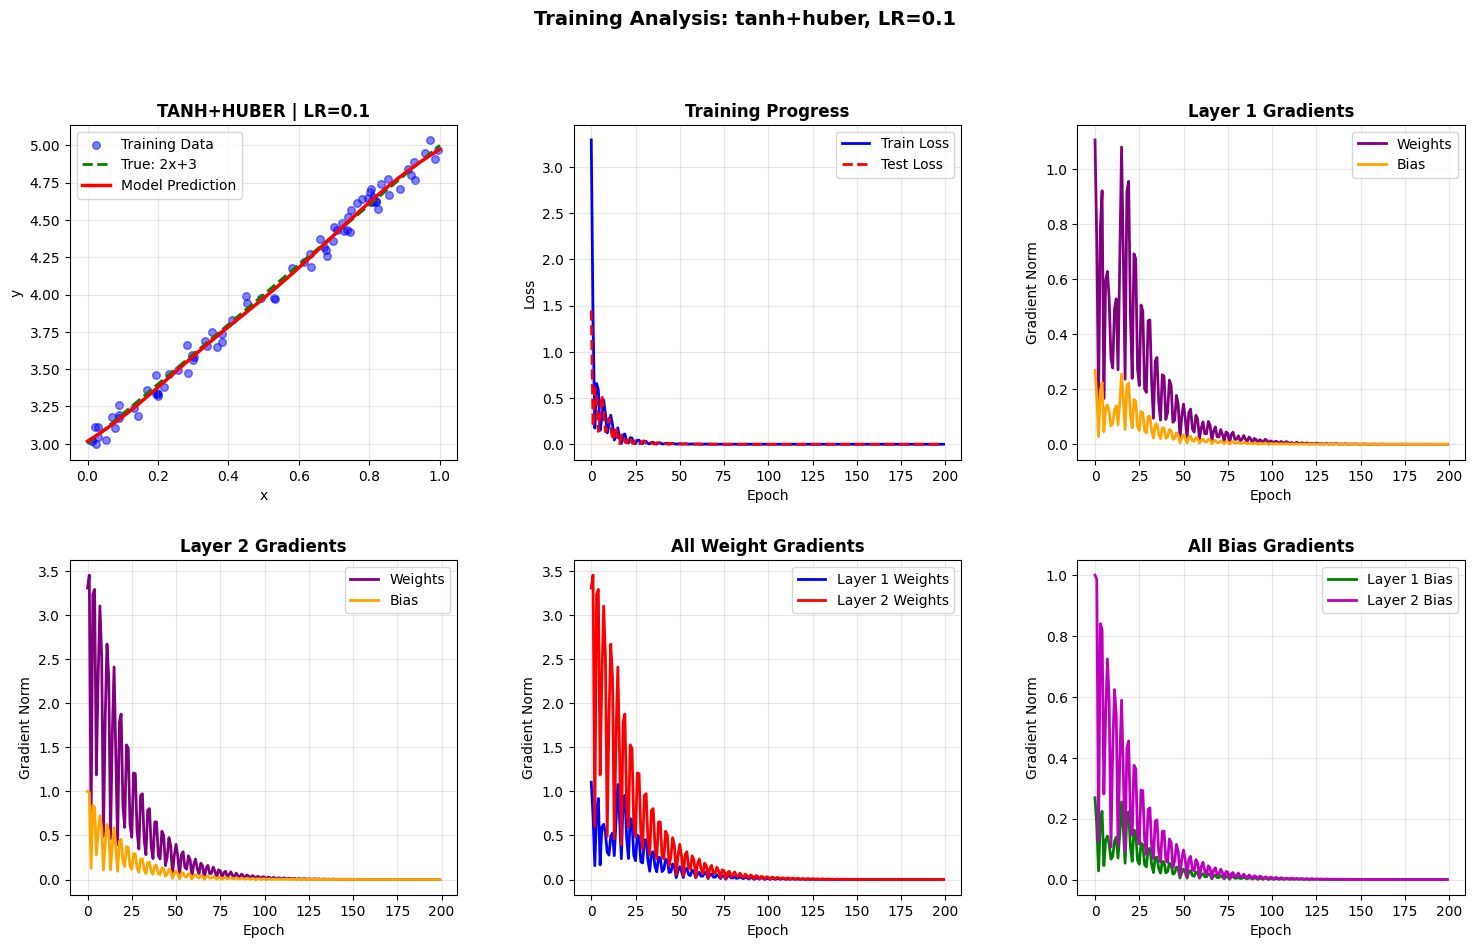


Rank 2: relu_huber_lr0.01


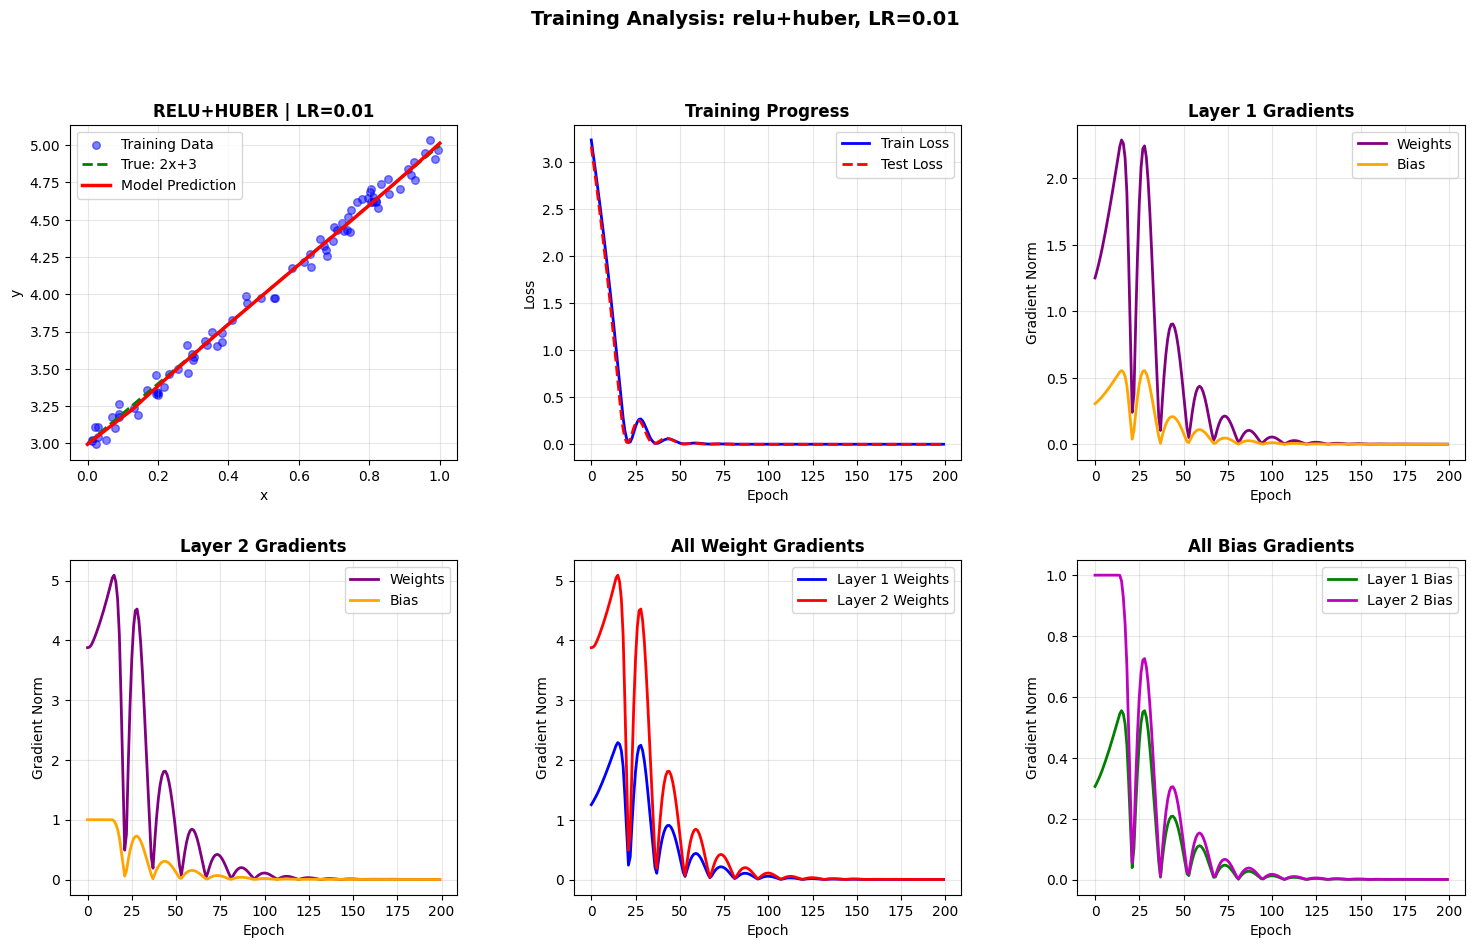


Rank 3: leaky_relu_huber_lr0.01


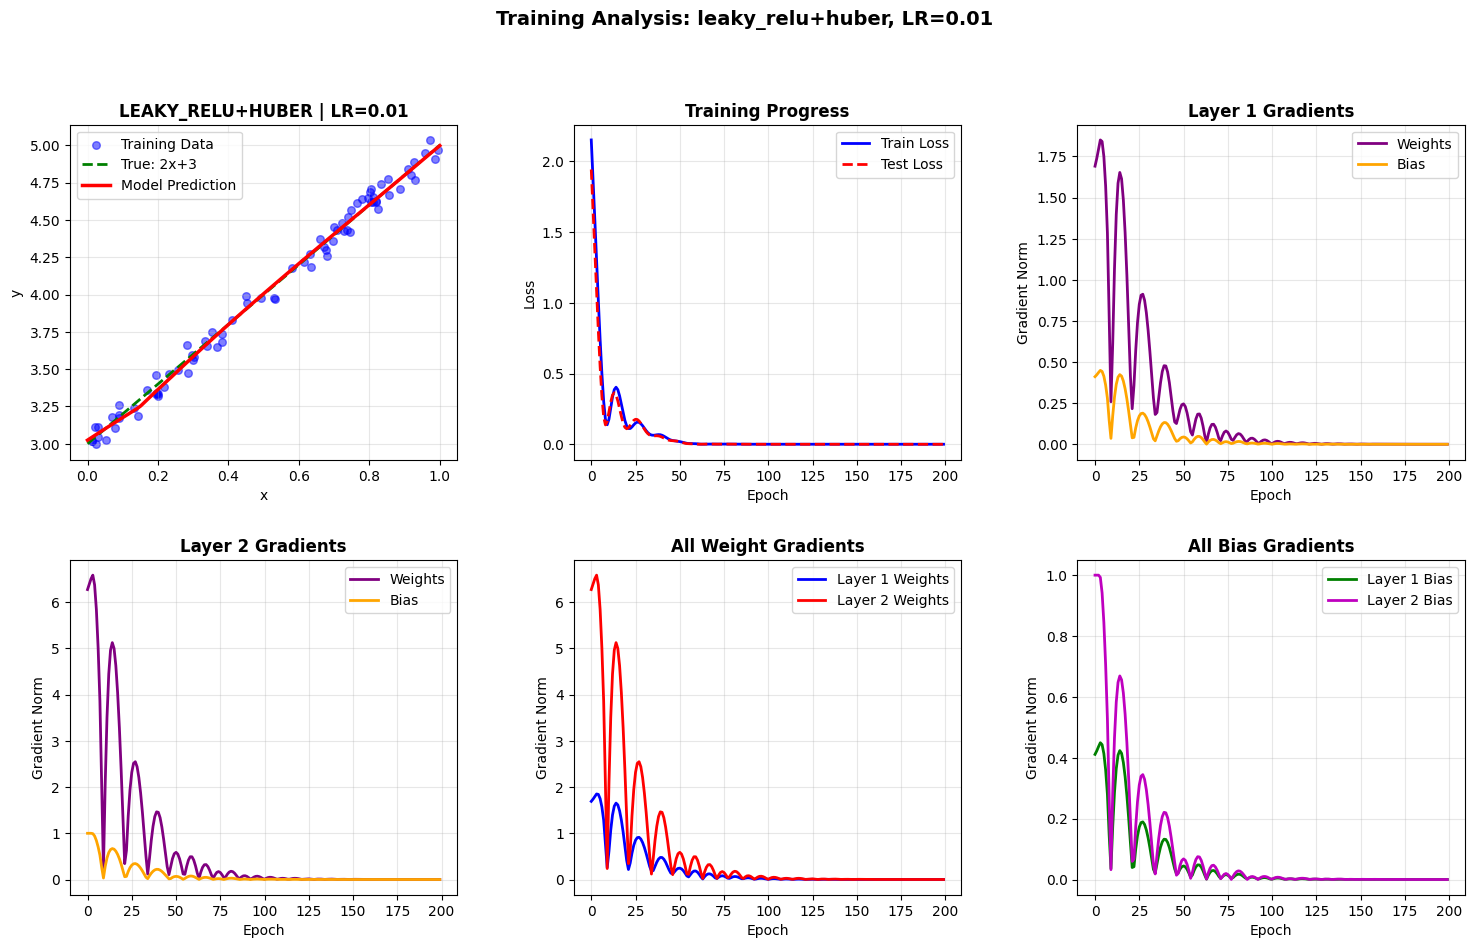


Rank 4: sigmoid_huber_lr0.1


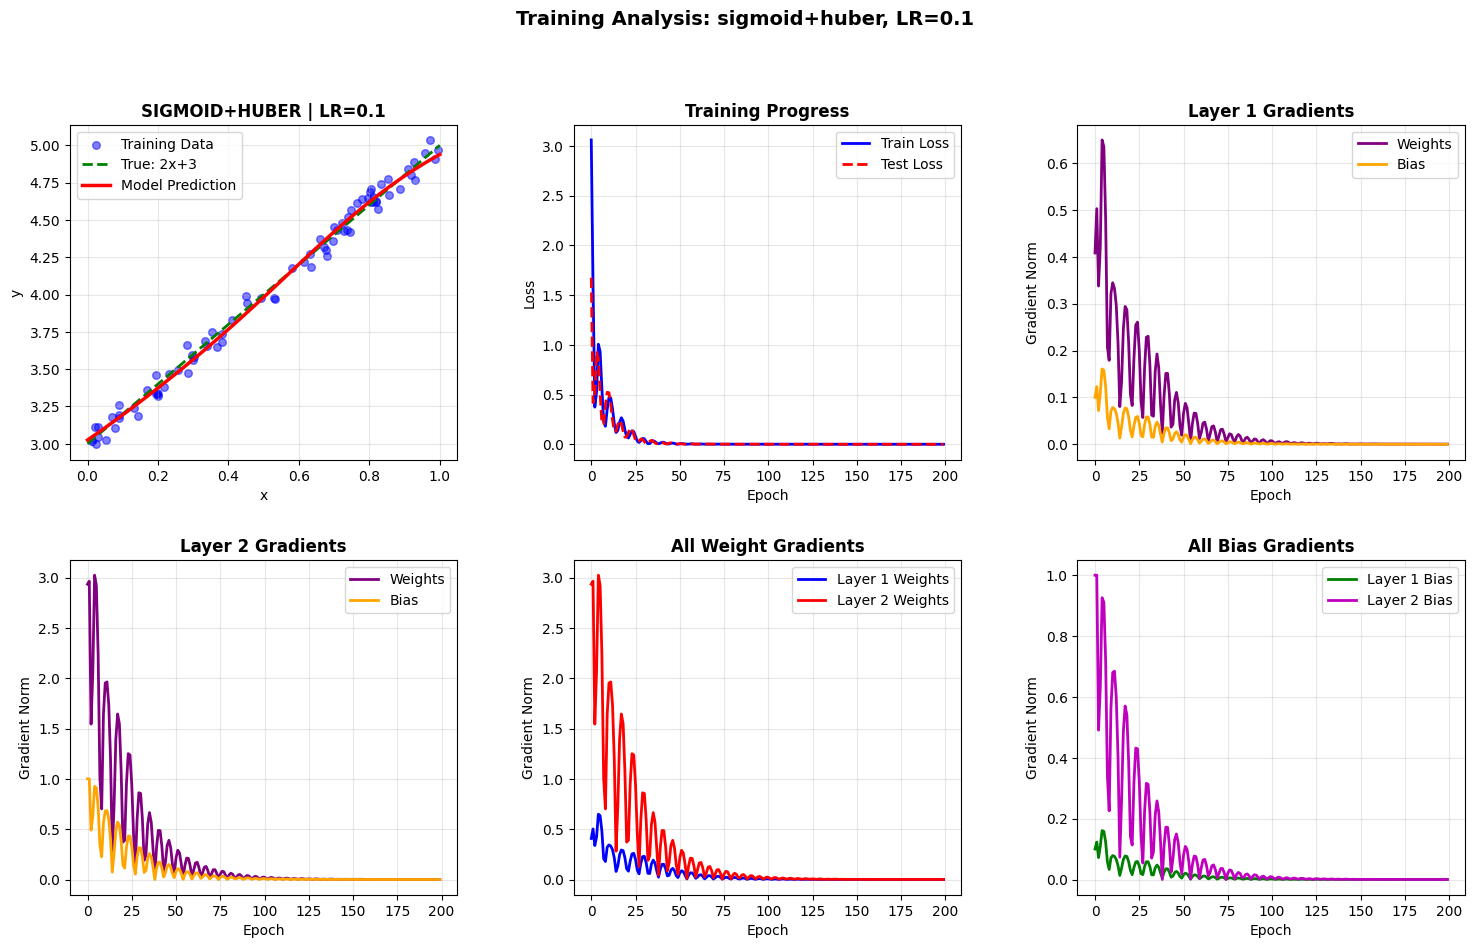


Rank 5: leaky_relu_huber_lr0.1


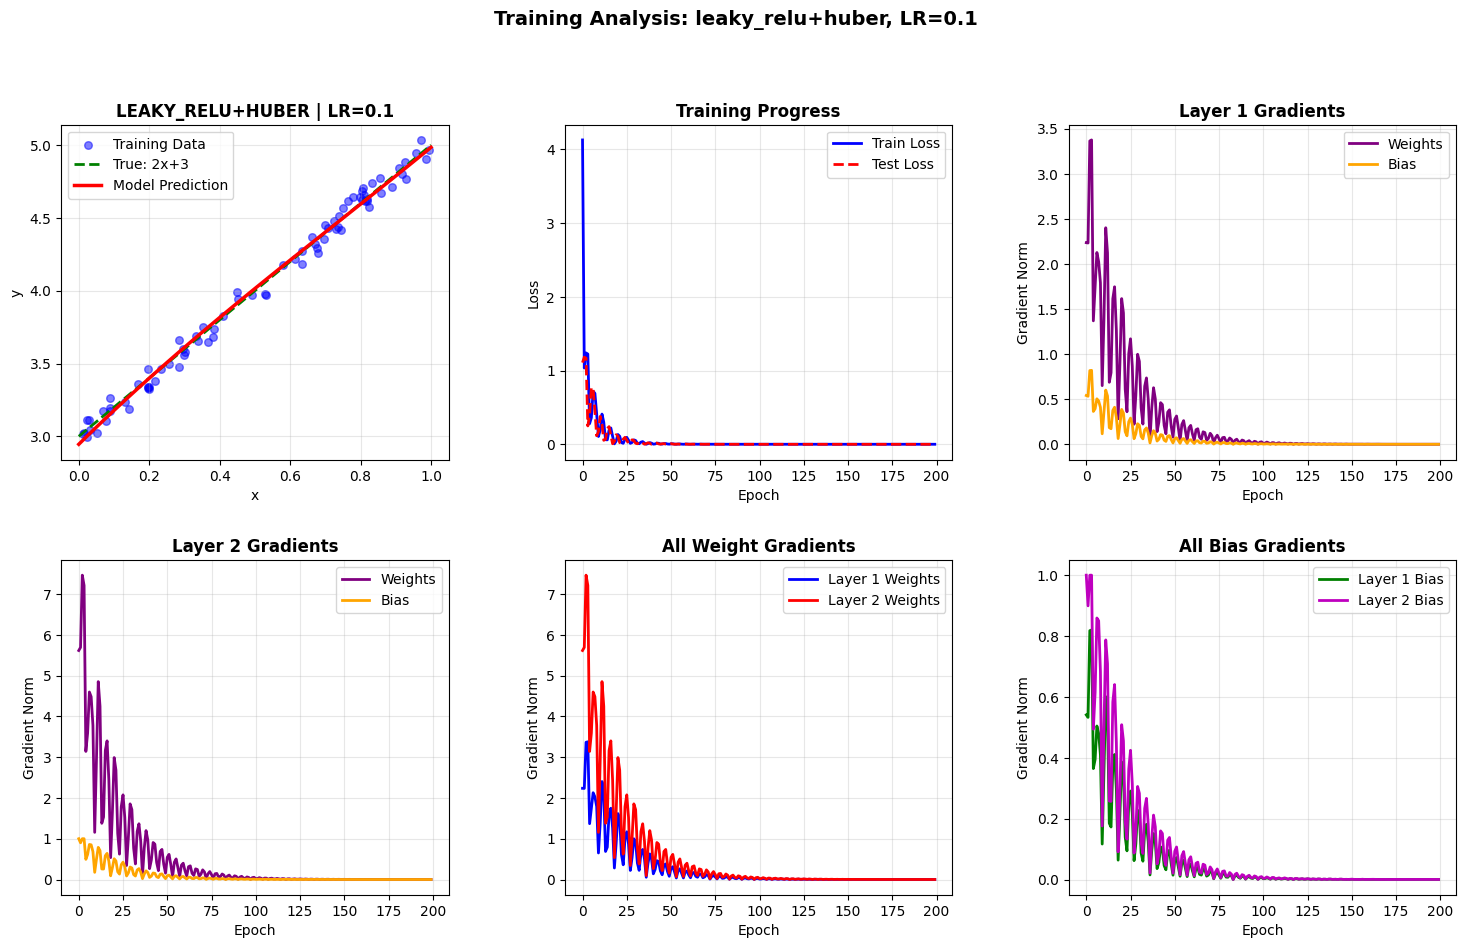


COMPLETE


In [5]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# DATA GENERATION
def generate_noisy_dataset(x_range, feature_transform, true_feature, number_of_samples, epsilon):
    x_values = np.random.uniform(x_range[0], x_range[1], number_of_samples)
    num_features = len(feature_transform)
    X = np.zeros((number_of_samples, num_features))

    for i, func in enumerate(feature_transform):
        X[:, i] = func(x_values)

    y_true = feature_transform[true_feature](x_values)
    noise = np.random.uniform(-epsilon, epsilon, number_of_samples)
    y = y_true + noise

    return X, y, x_values

# Define features
feature_transform = [
    lambda x: 2*x + 3,           # Linear (TRUE)
    lambda x: x**2 - 3*x + 2,    # Quadratic
    lambda x: 0.5*x**3 - x**2 + x  # Cubic
]

# Generate dataset
x_range = [0, 1]
noise = 0.1
n_samples = 100
true_feature = 0

X, y, x_values = generate_noisy_dataset(x_range, feature_transform, true_feature, n_samples, noise)
X_train, X_test, y_train, y_test, x_train, x_test = train_test_split(
    X, y, x_values, test_size=0.2, random_state=42
)

# Convert to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train)
y_train_tensor = torch.FloatTensor(y_train).reshape(-1, 1)
X_test_tensor = torch.FloatTensor(X_test)
y_test_tensor = torch.FloatTensor(y_test).reshape(-1, 1)

print(f"{'='*60}")
print(f"Dataset: True Function: 2x + 3, Noise: {noise}, Samples: {n_samples}")
print(f"Training samples: {len(X_train)}, Test samples: {len(X_test)}")
print('='*60)

# NEURAL NETWORK DEFINITION
class SimpleNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, activation):
        super(SimpleNN, self).__init__()
        self.layer1 = nn.Linear(input_dim, hidden_dim)
        self.activation = activation
        self.layer2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.layer1(x)
        x = self.activation(x)
        x = self.layer2(x)
        return x

# HYPERPARAMETERS
activations = {
    'relu': nn.ReLU(),
    'tanh': nn.Tanh(),
    'sigmoid': nn.Sigmoid(),
    'leaky_relu': nn.LeakyReLU(0.01),
}

losses = {
    'mse': nn.MSELoss(),
    'mae': nn.L1Loss(),
    'huber': nn.HuberLoss(),
}

learning_rates = [0.001, 0.01, 0.1, 1, 10]

# TRAINING FUNCTION WITH GRADIENT TRACKING
def train_single_combination(X_train, y_train, X_test, y_test,
                             activation_fn, loss_fn,
                             n_epochs=200, hidden_dim=20, lr=0.01):
    """Train a FRESH neural network and track gradients every epoch."""

    # CREATE NEW MODEL
    model = SimpleNN(input_dim=3, hidden_dim=hidden_dim, output_dim=1, activation=activation_fn)
    criterion = loss_fn
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Storage for tracking
    history = {
        'epochs': [],
        'train_losses': [],
        'test_losses': [],
        # Gradient tracking
        'layer1_weight_grad_norm': [],
        'layer1_bias_grad_norm': [],
        'layer2_weight_grad_norm': [],
        'layer2_bias_grad_norm': [],
    }

    # Training loop
    for epoch in range(n_epochs):
        model.train()
        optimizer.zero_grad()

        outputs = model(X_train)
        loss = criterion(outputs, y_train)

        # Check for NaN or Inf
        if torch.isnan(loss) or torch.isinf(loss):
            print(f"    ⚠ Training diverged at epoch {epoch}")
            break

        loss.backward()

        # Capture gradients BEFORE optimizer step
        layer1_w_grad = model.layer1.weight.grad.norm().item() if model.layer1.weight.grad is not None else 0
        layer1_b_grad = model.layer1.bias.grad.norm().item() if model.layer1.bias.grad is not None else 0
        layer2_w_grad = model.layer2.weight.grad.norm().item() if model.layer2.weight.grad is not None else 0
        layer2_b_grad = model.layer2.bias.grad.norm().item() if model.layer2.bias.grad is not None else 0

        optimizer.step()

        # Evaluate on test set
        model.eval()
        with torch.no_grad():
            test_pred = model(X_test)
            test_loss = criterion(test_pred, y_test)

        # Store history
        history['epochs'].append(epoch)
        history['train_losses'].append(loss.item())
        history['test_losses'].append(test_loss.item())
        history['layer1_weight_grad_norm'].append(layer1_w_grad)
        history['layer1_bias_grad_norm'].append(layer1_b_grad)
        history['layer2_weight_grad_norm'].append(layer2_w_grad)
        history['layer2_bias_grad_norm'].append(layer2_b_grad)

    # Final evaluation
    model.eval()
    with torch.no_grad():
        final_train_pred = model(X_train)
        final_train_loss = criterion(final_train_pred, y_train).item()

        final_test_pred = model(X_test)
        final_test_loss = criterion(final_test_pred, y_test).item()

    return model, history, final_train_loss, final_test_loss

# PLOTTING FUNCTION
def plot_training_results(history, x_train, y_train, model, activation_name, loss_name, lr):
    """Create comprehensive plots for training results."""

    fig = plt.figure(figsize=(18, 10))
    gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.3)

    # ===== Plot 1: Final Predictions =====
    ax1 = fig.add_subplot(gs[0, 0])
    x_line = np.linspace(0, 1, 100)
    y_true_line = 2 * x_line + 3

    # Get model predictions
    X_line = torch.zeros(100, 3)
    for i, func in enumerate(feature_transform):
        X_line[:, i] = torch.FloatTensor([func(x) for x in x_line])

    model.eval()
    with torch.no_grad():
        y_pred = model(X_line).numpy().flatten()

    ax1.scatter(x_train, y_train, alpha=0.5, s=30, c='blue', label='Training Data')
    ax1.plot(x_line, y_true_line, 'g--', linewidth=2, label='True: 2x+3')
    ax1.plot(x_line, y_pred, 'r-', linewidth=2.5, label='Model Prediction')
    ax1.set_xlabel('x')
    ax1.set_ylabel('y')
    ax1.set_title(f'{activation_name.upper()}+{loss_name.upper()} | LR={lr}', fontweight='bold')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # ===== Plot 2: Loss Curves =====
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.plot(history['epochs'], history['train_losses'], 'b-', linewidth=2, label='Train Loss')
    ax2.plot(history['epochs'], history['test_losses'], 'r--', linewidth=2, label='Test Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.set_title('Training Progress', fontweight='bold')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # ===== Plot 3: Layer 1 Gradients =====
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.plot(history['epochs'], history['layer1_weight_grad_norm'],
             'purple', linewidth=2, label='Weights')
    ax3.plot(history['epochs'], history['layer1_bias_grad_norm'],
             'orange', linewidth=2, label='Bias')
    ax3.set_xlabel('Epoch')
    ax3.set_ylabel('Gradient Norm')
    ax3.set_title('Layer 1 Gradients', fontweight='bold')
    ax3.legend()
    ax3.grid(True, alpha=0.3)

    # ===== Plot 4: Layer 2 Gradients =====
    ax4 = fig.add_subplot(gs[1, 0])
    ax4.plot(history['epochs'], history['layer2_weight_grad_norm'],
             'purple', linewidth=2, label='Weights')
    ax4.plot(history['epochs'], history['layer2_bias_grad_norm'],
             'orange', linewidth=2, label='Bias')
    ax4.set_xlabel('Epoch')
    ax4.set_ylabel('Gradient Norm')
    ax4.set_title('Layer 2 Gradients', fontweight='bold')
    ax4.legend()
    ax4.grid(True, alpha=0.3)

    # ===== Plot 5: All Weight Gradients =====
    ax5 = fig.add_subplot(gs[1, 1])
    ax5.plot(history['epochs'], history['layer1_weight_grad_norm'],
             'b-', linewidth=2, label='Layer 1 Weights')
    ax5.plot(history['epochs'], history['layer2_weight_grad_norm'],
             'r-', linewidth=2, label='Layer 2 Weights')
    ax5.set_xlabel('Epoch')
    ax5.set_ylabel('Gradient Norm')
    ax5.set_title('All Weight Gradients', fontweight='bold')
    ax5.legend()
    ax5.grid(True, alpha=0.3)

    # ===== Plot 6: All Bias Gradients =====
    ax6 = fig.add_subplot(gs[1, 2])
    ax6.plot(history['epochs'], history['layer1_bias_grad_norm'],
             'g-', linewidth=2, label='Layer 1 Bias')
    ax6.plot(history['epochs'], history['layer2_bias_grad_norm'],
             'm-', linewidth=2, label='Layer 2 Bias')
    ax6.set_xlabel('Epoch')
    ax6.set_ylabel('Gradient Norm')
    ax6.set_title('All Bias Gradients', fontweight='bold')
    ax6.legend()
    ax6.grid(True, alpha=0.3)

    plt.suptitle(f'Training Analysis: {activation_name}+{loss_name}, LR={lr}',
                 fontsize=14, fontweight='bold', y=0.995)

    return fig

# TRAIN ALL COMBINATIONS
print("\n" + "="*70)
print("TRAINING WITH GRADIENT TRACKING")
print("="*70)
print(f"\nTotal Combinations: {len(activations) * len(losses) * len(learning_rates)}")
print("="*70)

results = {}
experiment_count = 0
total_experiments = len(activations) * len(losses) * len(learning_rates)

for lr in learning_rates:
    print(f"\n{'='*70}")
    print(f"LEARNING RATE: {lr}")
    print('='*70)

    for activation_name, activation_fn in activations.items():
        for loss_name, loss_fn in losses.items():
            experiment_count += 1
            combo_name = f"{activation_name}_{loss_name}_lr{lr}"

            print(f"\n[{experiment_count}/{total_experiments}] {combo_name}")

            model, history, final_train_loss, final_test_loss = train_single_combination(
                X_train_tensor, y_train_tensor,
                X_test_tensor, y_test_tensor,
                activation_fn, loss_fn,
                n_epochs=200, hidden_dim=20, lr=lr
            )

            results[combo_name] = {
                'activation': activation_name,
                'loss': loss_name,
                'lr': lr,
                'model': model,
                'history': history,
                'final_train_loss': final_train_loss,
                'final_test_loss': final_test_loss
            }

            print(f"  ✓ Train: {final_train_loss:.4f} | Test: {final_test_loss:.4f}")

# RESULTS SUMMARY
print("\n" + "="*70)
print("RESULTS SUMMARY (Top 10)")
print("="*70)

sorted_results = sorted(results.items(), key=lambda x: x[1]['final_test_loss'])

print(f"\n{'Rank':<6} {'Combination':<35} {'LR':<8} {'Train':<12} {'Test':<12}")
print("-" * 80)

for rank, (combo_name, result) in enumerate(sorted_results[:10], 1):
    display_name = f"{result['activation']}_{result['loss']}"
    print(f"{rank:<6} {display_name:<35} {result['lr']:<8} "
          f"{result['final_train_loss']:<12.4f} {result['final_test_loss']:<12.4f}")

best_combo = sorted_results[0]
print(f"\n BEST: {best_combo[0]} | Test Loss: {best_combo[1]['final_test_loss']:.4f}")

# DISPLAY PLOTS FOR TOP 5 PERFORMERS
print("\n" + "="*70)
print("GENERATING PLOTS FOR TOP 5 PERFORMERS")
print("="*70)

for rank, (combo_name, result) in enumerate(sorted_results[:5], 1):
    print(f"\nRank {rank}: {combo_name}")
    fig = plot_training_results(
        result['history'],
        x_train,
        y_train,
        result['model'],
        result['activation'],
        result['loss'],
        result['lr']
    )
    plt.show()

print("\n" + "="*70)
print("COMPLETE")
print("="*70)